In [115]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import os
import kagglehub

In [116]:
# Plot style: soft light theme with strong contrast
plt.rcParams.update({
    'figure.facecolor': '#f8f9fc',
    'axes.facecolor':   '#ffffff',
    'axes.edgecolor':   '#cfd6e4',
    'axes.labelcolor':  '#2b3245',
    'axes.titlecolor':  '#1b2236',
    'axes.titleweight': 'bold',
    'axes.titlesize':   14,
    'axes.labelsize':   11,
    'axes.grid':        True,
    'axes.spines.top':  False,
    'axes.spines.right': False,
    'xtick.color':      '#5b6478',
    'ytick.color':      '#5b6478',
    'text.color':       '#2b3245',
    'grid.color':       '#e6eaf2',
    'grid.linestyle':   '--',
    'grid.linewidth':   0.8,
    'font.family':      'DejaVu Sans',
    'figure.dpi':       110,
    'savefig.dpi':      300,
    'lines.linewidth':  2,
    # Box plot styling (this is what fixes the visibility)
    'boxplot.boxprops.linewidth':     1.8,
    'boxplot.whiskerprops.linewidth': 1.8,
    'boxplot.capprops.linewidth':     1.8,
    'boxplot.medianprops.linewidth':  2.5,
    'boxplot.medianprops.color':      '#e8590c',
    'boxplot.flierprops.marker':      'o',
    'boxplot.flierprops.markersize':  4,
    'boxplot.flierprops.markerfacecolor': '#e03131',
    'boxplot.flierprops.markeredgecolor': 'none',
})

# Vibrant palette that works on a light background
ACCENT   = '#3b82f6'   # blue
GREEN    = '#10b981'   # emerald
RED      = '#ef4444'   # red
ORANGE   = '#f59e0b'   # amber
PURPLE   = '#8b5cf6'   # violet
TEAL     = '#14b8a6'

PALETTE = [ACCENT, GREEN, ORANGE, PURPLE, RED, TEAL]
sns.set_palette(PALETTE)

print('Libraries loaded successfully')

Libraries loaded successfully


In [117]:
df = pd.read_csv("/kaggle/input/datasets/jayjoshi37/sleep-screen-time-and-stress-analysis/sleep_mobile_stress_dataset_15000.csv")
df.head()

,user_id,age,gender,occupation,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,caffeine_intake_cups,physical_activity_minutes,notifications_received_per_day,mental_fatigue_score
0,1,56,Female,Designer,3.26,86,5.31,7.72,3.49,0,35,119,3.57
1,2,46,Female,Teacher,1.85,32,7.36,9.70,3.01,0,16,299,1.91
2,3,32,Female,Designer,3.04,107,4.50,6.38,5.03,0,17,21,6.05
3,4,25,Male,Software Engineer,9.00,36,6.68,5.53,10.00,0,3,220,9.92
4,5,38,Female,Teacher,3.52,56,7.57,6.69,6.71,4,92,167,5.99


In [118]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   user_id                           15000 non-null  int64  
 1   age                               15000 non-null  int64  
 2   gender                            15000 non-null  object 
 3   occupation                        15000 non-null  object 
 4   daily_screen_time_hours           15000 non-null  float64
 5   phone_usage_before_sleep_minutes  15000 non-null  int64  
 6   sleep_duration_hours              15000 non-null  float64
 7   sleep_quality_score               15000 non-null  float64
 8   stress_level                      15000 non-null  float64
 9   caffeine_intake_cups              15000 non-null  int64  
 10  physical_activity_minutes         15000 non-null  int64  
 11  notifications_received_per_day    15000 non-null  int64  
 12  ment

None

- Only `Gender` and `occupation` is object datatype

In [119]:
print("Total Unique Gender:",df['gender'].nunique())
print("Total Unique number of occupation:",df['occupation'].nunique(),end='\n\n')

print(df['gender'].value_counts(),end="\n\n")
print(df['occupation'].value_counts())

Total Unique Gender: 3
Total Unique number of occupation: 8

gender
Male      7234
Female    7181
Other      585
Name: count, dtype: int64

occupation
Manager              1962
Doctor               1922
Software Engineer    1917
Freelancer           1891
Student              1861
Researcher           1837
Designer             1813
Teacher              1797
Name: count, dtype: int64


In [120]:
df.isna().sum()

user_id                             0
age                                 0
gender                              0
occupation                          0
daily_screen_time_hours             0
phone_usage_before_sleep_minutes    0
sleep_duration_hours                0
sleep_quality_score                 0
stress_level                        0
caffeine_intake_cups                0
physical_activity_minutes           0
notifications_received_per_day      0
mental_fatigue_score                0
dtype: int64

- No Empty Values

In [121]:
df.duplicated().sum()

np.int64(0)

- There's no duplicate values

In [122]:
summary = df.describe().T

summary['mean_median_diff'] = (
    summary['mean'] - summary['50%']
)

display(summary)

,count,mean,std,min,25%,50%,75%,max,mean_median_diff
user_id,15000.0,7500.500000,4330.271354,1.0,3750.75,7500.50,11250.25,15000.0,0.000000
age,15000.0,38.488467,12.007970,18.0,28.00,38.00,49.00,59.0,0.488467
daily_screen_time_hours,15000.0,5.501528,2.600085,1.0,3.26,5.49,7.76,10.0,0.011528
phone_usage_before_sleep_minutes,15000.0,59.708933,34.641858,0.0,29.00,60.00,90.00,119.0,-0.291067
sleep_duration_hours,15000.0,6.509683,1.452689,4.0,5.26,6.49,7.79,9.0,0.019683
sleep_quality_score,15000.0,6.246362,1.713644,1.0,5.00,6.25,7.50,10.0,-0.003638
stress_level,15000.0,6.980247,2.749382,1.0,4.75,7.38,10.00,10.0,-0.399753
caffeine_intake_cups,15000.0,1.998800,1.414590,0.0,1.00,2.00,3.00,4.0,-0.001200
physical_activity_minutes,15000.0,59.157133,34.525705,0.0,29.00,59.00,89.00,119.0,0.157133
notifications_received_per_day,15000.0,160.890467,80.856902,20.0,92.00,162.00,231.00,299.0,-1.109533


In [123]:
skewed_cols = summary[np.abs(summary['mean_median_diff']) > 0.35].index.tolist()

for col in skewed_cols:
    print(f"{col}: {df[col].skew():.3f}")

age: 0.008
stress_level: -0.466
notifications_received_per_day: -0.020
mental_fatigue_score: -0.511


- `age` and `notifications_received_per_day` is close to 0, means they are approximately symmetric
- `mental_fatigue_score` and `stress_level` is less than 0; means it's negative skew (left skew)

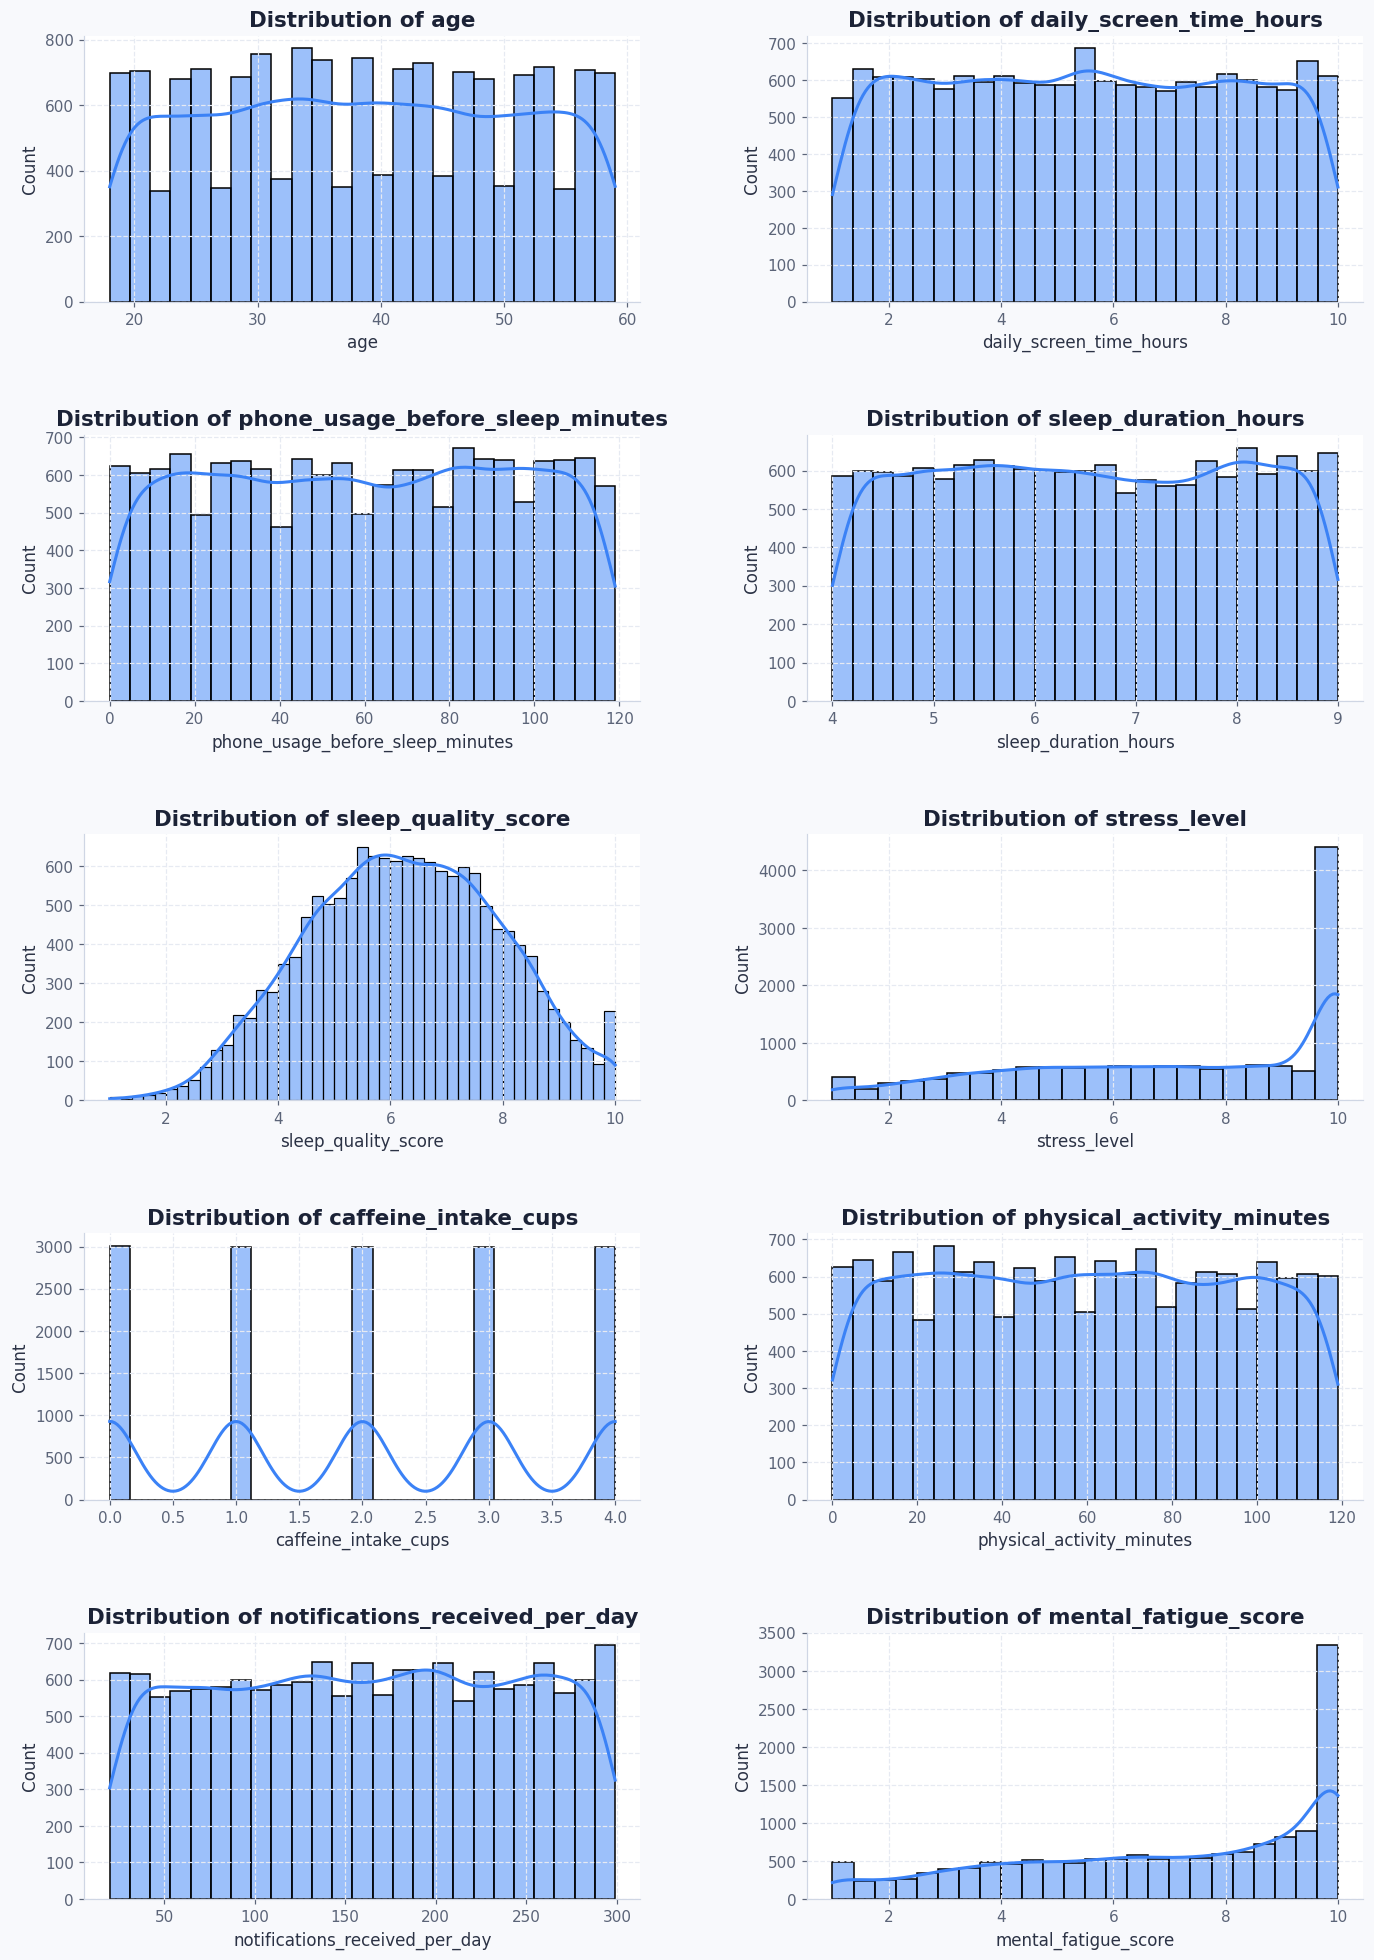

In [124]:
numerical_cols = df.select_dtypes(include=['float64','int64']).drop(columns=['user_id']).columns

fig,axes = plt.subplots(5,2,figsize=(15,22))

for col, ax in zip(numerical_cols,axes.flatten()):
    sns.histplot(data=df,x=col,ax=ax,kde=True)
    ax.set_title(f'Distribution of {col}')

plt.subplots_adjust(hspace=0.5,wspace=0.3)
plt.show()

- `sleep_quality_score` resembles bell-shaped curve
- `mental_fatigue_score` and `stress_level` are Negatively skewed (left skewed)
- `caffeine_intake_cups` has discrete uniform distribution
- Rest of features are approximately uniform distributed
---
- Negatively skewed causes here `celeing_effect` many observations accumulate at the maximum possible value of a measurement

In [131]:
ceil_cols = ['stress_level', 'mental_fatigue_score',
        'sleep_quality_score']

for col in ceil_cols:
    count = (df[col] == 10).sum()
    percentage = count / len(df) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

stress_level: 3875 (25.83%)
mental_fatigue_score: 2484 (16.56%)
sleep_quality_score: 153 (1.02%)


- `strees_level` and `mental_fatigue_score` have substantial ceiling effect

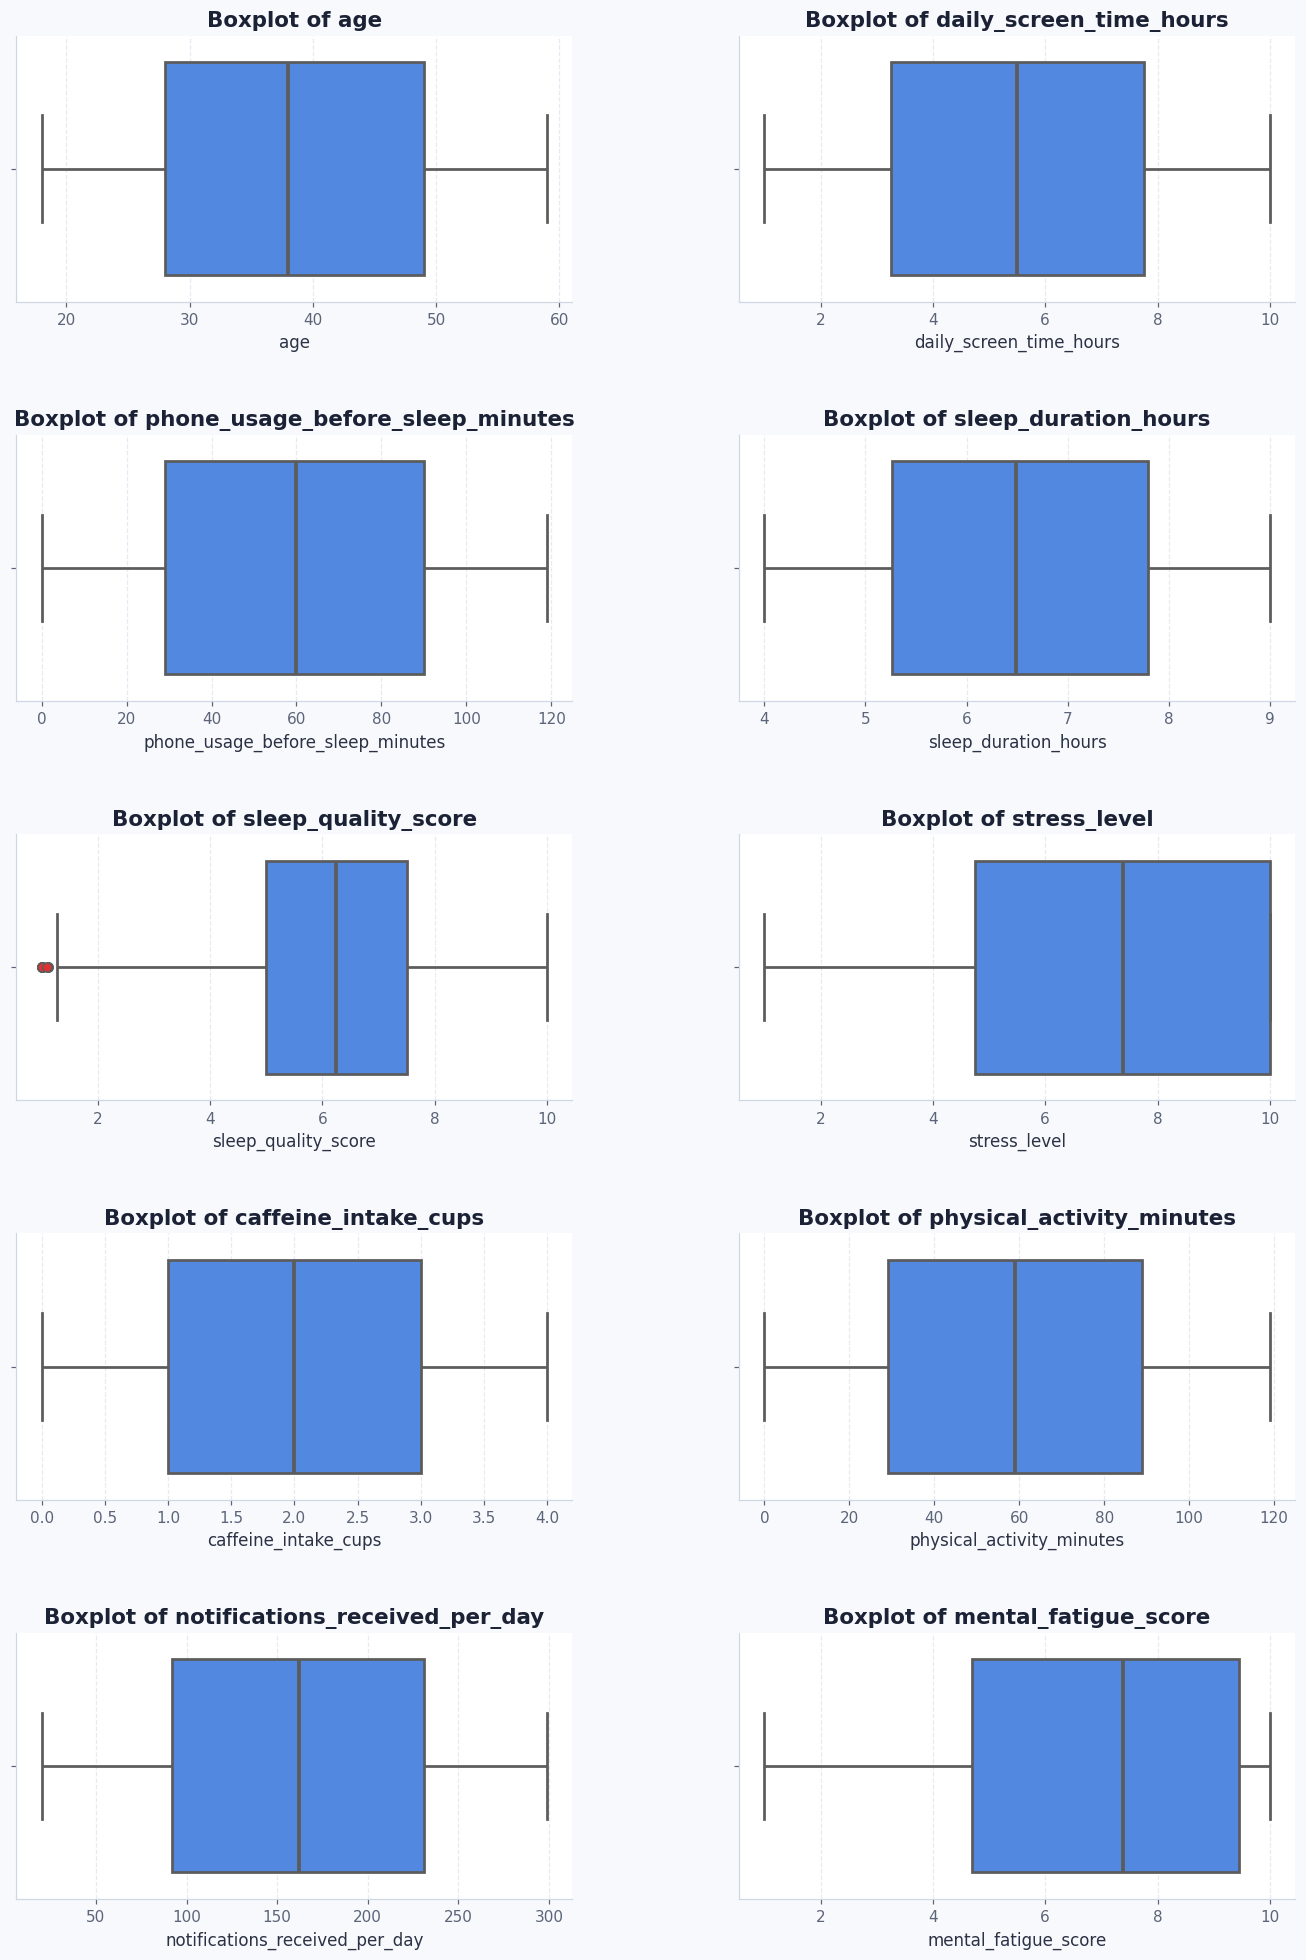

In [126]:
numerical_cols = df.select_dtypes(include=['float64','int64']).drop(columns=['user_id']).columns

fig,axes = plt.subplots(5,2,figsize=(15,22))

for col, ax in zip(numerical_cols,axes.flatten()):
    sns.boxplot(data=df,x=col,ax=ax)
    ax.set_title(f'Boxplot of {col}')

plt.subplots_adjust(hspace=0.5,wspace=0.3)
plt.show()

- Only `sleep_quality_score` has outlier

In [132]:
df.loc[:,ceil_cols].describe()

,stress_level,mental_fatigue_score,sleep_quality_score
count,15000.000000,15000.000000,15000.000000
mean,6.980247,6.873009,6.246362
std,2.749382,2.730482,1.713644
min,1.000000,1.000000,1.000000
25%,4.750000,4.700000,5.000000
50%,7.380000,7.380000,6.250000
75%,10.000000,9.450000,7.500000
max,10.000000,10.000000,10.000000


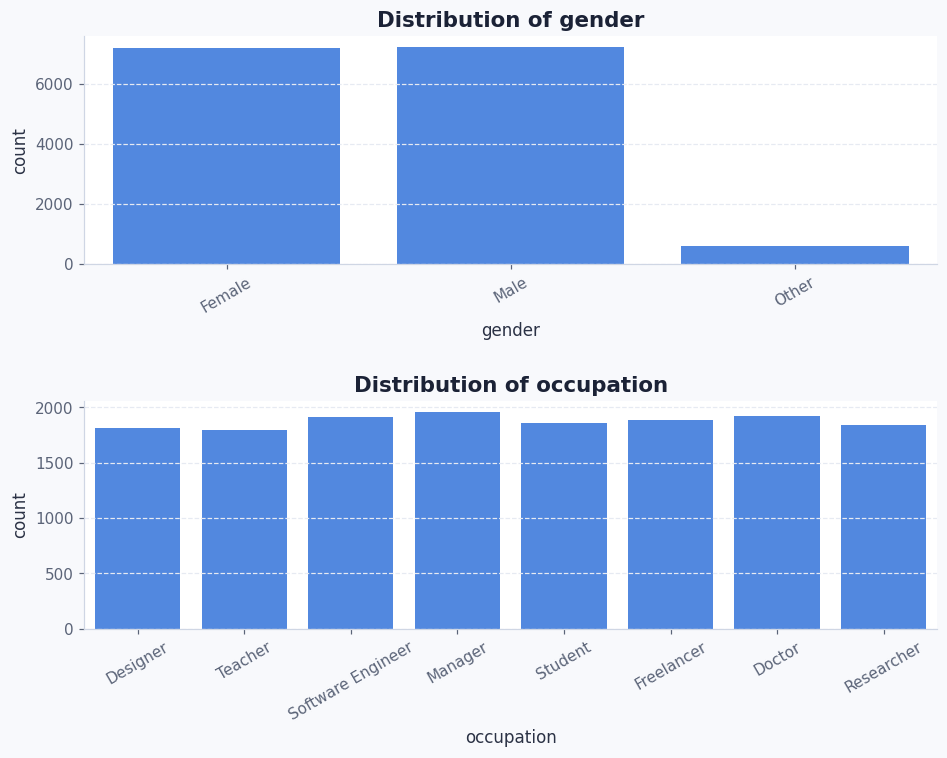

In [129]:
categorical_cols = df.select_dtypes(include=['object']).columns

fig,axes = plt.subplots(2,1,figsize=(10,7))
for col,ax in zip(categorical_cols,axes.flatten()):
    distribution = df[col].value_counts()
    # ax.bar(distribution.index,distribution.values)
    sns.countplot(data=df,x=col,ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis='x',rotation=30)

plt.subplots_adjust(hspace=0.6,wspace=0.3)
plt.show()